# 03. 모델 학습과 판정 규칙 결정 — PROTOCOL.md 3~5절

학습 데이터만 사용한다. 이 노트북에는 평가 데이터 점수가 없다.

1. 시간순 교차검증으로 두 모델의 설정값을 고른다 (4절)
2. 고른 설정을 `reports/best_params.json`에 고정한다
3. 판정 방식(A 고정 기준값 / B 묶음 내 할당량)을 학습 데이터 규칙으로 정한다 (5절)

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data import load_train

sns.set_theme(style="whitegrid")
REPORT_DIR = ROOT / "reports"
FIG_DIR = REPORT_DIR / "figures"
X, y, ts = load_train()

from sklearn.model_selection import TimeSeriesSplit
from src.models import build_logistic, build_lightgbm, tune, readable_params, build_from_params, LOGISTIC_GRID, LIGHTGBM_GRID, N_SPLITS
from src.evaluate import oof_by_fold, fixed_cutoff_drift, choose_rule, INSPECT_RATE, DRIFT_TOLERANCE

## 1. 교차검증 구간

```
fold 1: [학습        ][검증]
fold 2: [학습              ][검증]
fold 3: [학습                    ][검증]
fold 4: [학습                          ][검증]
```

In [2]:
pd.DataFrame([
    {"fold": i + 1, "학습 행": len(tr), "검증 행": len(va), "검증 불량 수": int(y.iloc[va].sum()),
     "검증 기간": f"{ts.iloc[va[0]]:%m-%d} ~ {ts.iloc[va[-1]]:%m-%d}"}
    for i, (tr, va) in enumerate(TimeSeriesSplit(N_SPLITS).split(X))
])

,fold,학습 행,검증 행,검증 불량 수,검증 기간
0,1,235,235,26,08-17 ~ 08-28
1,2,470,235,8,08-28 ~ 09-02
2,3,705,235,10,09-02 ~ 09-20
3,4,940,235,4,09-20 ~ 09-29


검증 구간마다 불량이 4~26개뿐이라 fold별 점수가 크게 흔들릴 수 있다. 평균과 함께 표준편차를 본다.

## 2. 설정값 선택

In [3]:
searches = {
    "logistic": tune(build_logistic(), LOGISTIC_GRID, X, y),
    "lightgbm": tune(build_lightgbm(), LIGHTGBM_GRID, X, y),
}

def cv_table(search, top=6):
    res = pd.DataFrame(search.cv_results_)
    params = pd.DataFrame([readable_params(p) for p in res["params"]])
    folds = res[[f"split{i}_test_score" for i in range(N_SPLITS)]]
    folds.columns = [f"fold{i+1}" for i in range(N_SPLITS)]
    out = pd.concat([params, res[["mean_test_score", "std_test_score"]].rename(
        columns={"mean_test_score": "CV 평균", "std_test_score": "CV 표준편차"}), folds], axis=1)
    return out.sort_values("CV 평균", ascending=False).head(top).round(3)

print("로지스틱 회귀"); display(cv_table(searches["logistic"]))
print("LightGBM"); display(cv_table(searches["lightgbm"]))

로지스틱 회귀


,C,add_indicator,CV 평균,CV 표준편차,fold1,fold2,fold3,fold4
1,0.001,True,0.095,0.054,0.104,0.083,0.171,0.020
0,0.001,False,0.092,0.049,0.104,0.161,0.081,0.023
3,0.010,True,0.073,0.029,0.098,0.079,0.092,0.025
2,0.010,False,0.068,0.030,0.103,0.082,0.067,0.022
5,0.100,True,0.065,0.027,0.098,0.060,0.077,0.025
4,0.100,False,0.064,0.029,0.102,0.074,0.057,0.021


LightGBM


,colsample_bytree,max_depth,add_indicator,CV 평균,CV 표준편차,fold1,fold2,fold3,fold4
0,0.1,2,False,0.174,0.194,0.143,0.037,0.500,0.019
3,0.1,3,True,0.174,0.187,0.148,0.038,0.488,0.022
5,0.3,2,True,0.171,0.191,0.137,0.037,0.493,0.019
1,0.1,2,True,0.163,0.165,0.155,0.042,0.435,0.019
2,0.1,3,False,0.163,0.171,0.145,0.038,0.447,0.022
7,0.3,3,True,0.162,0.181,0.125,0.039,0.468,0.018


In [4]:
best_params = {name: readable_params(s.best_params_) for name, s in searches.items()}
summary = pd.DataFrame({
    name: {"설정": best_params[name], "CV PR-AUC 평균": s.best_score_,
           "CV 표준편차": s.cv_results_["std_test_score"][s.best_index_]}
    for name, s in searches.items()
}).T
summary["학습 불량 비율 (무작위 기준)"] = y.mean()
summary

,설정,CV PR-AUC 평균,CV 표준편차,학습 불량 비율 (무작위 기준)
logistic,"{'C': 0.001, 'add_indicator': True}",0.094585,0.053662,0.068085
lightgbm,"{'colsample_bytree': 0.1, 'max_depth': 2, 'add...",0.17444,0.193645,0.068085


**해석**: 선택 기준은 계획서대로 **CV 평균**이다. 표준편차가 크다는 점은 결과 해석 때 함께 언급한다.
두 모델 모두 평가 데이터에서 보고하므로, 여기서 한쪽을 고르지 않는다.

## 3. 판정 방식 결정 (PROTOCOL.md 5절)

고른 설정으로 fold별 교차검증 예측을 다시 만든다. fold 2~4 각각에 대해, **이전 fold들의 예측**으로 상위 20% 경계값(A의 기준값)을 구하고
그 fold에 적용했을 때 실제로 몇 %가 걸러지는지 본다. 평균 5%p 넘게 어긋나면 B(묶음 내 상위 20%)를 쓴다.

In [5]:
rules, drift_tables = {}, {}
for name, params in best_params.items():
    folds = oof_by_fold(build_from_params(name, params), X, y)
    drift = fixed_cutoff_drift(folds)
    drift_tables[name] = drift
    rules[name] = choose_rule(drift)
    print(f"{name}: 평균 |차이| = {drift['20%와의 차이'].abs().mean():.3f} (허용 {DRIFT_TOLERANCE}) → {rules[name]}")
    display(drift.round(3))

logistic: 평균 |차이| = 0.055 (허용 0.05) → B_batch_quota


,fold,기준값,판정 비율,20%와의 차이
0,2,0.505,0.132,-0.068
1,3,0.493,0.204,0.004
2,4,0.494,0.106,-0.094


lightgbm: 평균 |차이| = 0.094 (허용 0.05) → B_batch_quota


,fold,기준값,판정 비율,20%와의 차이
0,2,0.279,0.243,0.043
1,3,0.286,0.098,-0.102
2,4,0.262,0.064,-0.136


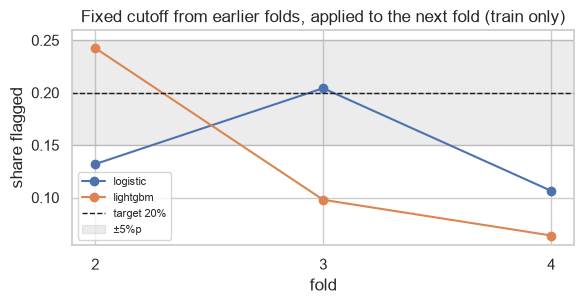

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.2))
for name, d in drift_tables.items():
    ax.plot(d["fold"], d["판정 비율"], "o-", label=name)
ax.axhline(INSPECT_RATE, color="k", ls="--", lw=1, label="target 20%")
ax.axhspan(INSPECT_RATE - DRIFT_TOLERANCE, INSPECT_RATE + DRIFT_TOLERANCE, color="gray", alpha=0.15, label="±5%p")
ax.set_xticks([2, 3, 4]); ax.set_xlabel("fold"); ax.set_ylabel("share flagged")
ax.set_title("Fixed cutoff from earlier folds, applied to the next fold (train only)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "07_cutoff_drift_train.png", dpi=150)

**해석**
- 학습 기간 안에서도 이전 시기로 정한 기준값을 다음 시기에 적용하면 판정 비율이 6%~24%로 흔들린다.
  시기가 바뀌면 모델 확률이 전체적으로 이동하기 때문이다.
- LightGBM은 평균 9.4%p 어긋나 확실히 B다. 로지스틱 회귀는 5.5%p로 기준(5%p)을 **근소하게** 넘었다.
  기준 근처라 결과가 달라질 수도 있었지만, 계획서 규칙대로 B를 쓴다.

## 4. 결정 고정

In [7]:
decisions = {name: {"params": best_params[name], "rule": rules[name]} for name in best_params}
(REPORT_DIR / "best_params.json").write_text(json.dumps(decisions, indent=2, ensure_ascii=False))
summary.to_csv(REPORT_DIR / "cv_summary.csv", encoding="utf-8-sig")
decisions

{'logistic': {'params': {'C': 0.001, 'add_indicator': True},
  'rule': 'B_batch_quota'},
 'lightgbm': {'params': {'colsample_bytree': 0.1,
   'max_depth': 2,
   'add_indicator': False},
  'rule': 'B_batch_quota'}}

이 결정은 평가 데이터를 열기 전에 커밋한다. `scripts/final_evaluation.py`는 이 파일만 읽어서 평가한다.